In [1]:
import csv
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

In [ ]:
# File/Folder Paths
# PROJECT_ROOT = Path(__file__).resolve().parents[1]
PROJECT_ROOT = Path.cwd().parents[0]
PATCH_DIR = (PROJECT_ROOT/"data"/"SSDD"/"background_patches")
METADATA_FILE = PATCH_DIR / "metadata.csv"

In [3]:
# Loading the metadata
with open(METADATA_FILE, "r") as f:
    reader = csv.DictReader(f)
    metadata = list(reader)

In [4]:
# Selecting random patches
random.seed(42)
samples = random.sample(metadata, min(25, len(metadata)))

Saved visualization to: /media/aryakumar/ACER/ARYAKUMAR-MISHRA/Projects/Machine-Learning/SAR_Anomaly_Detection/outputs/background_patch_examples.png


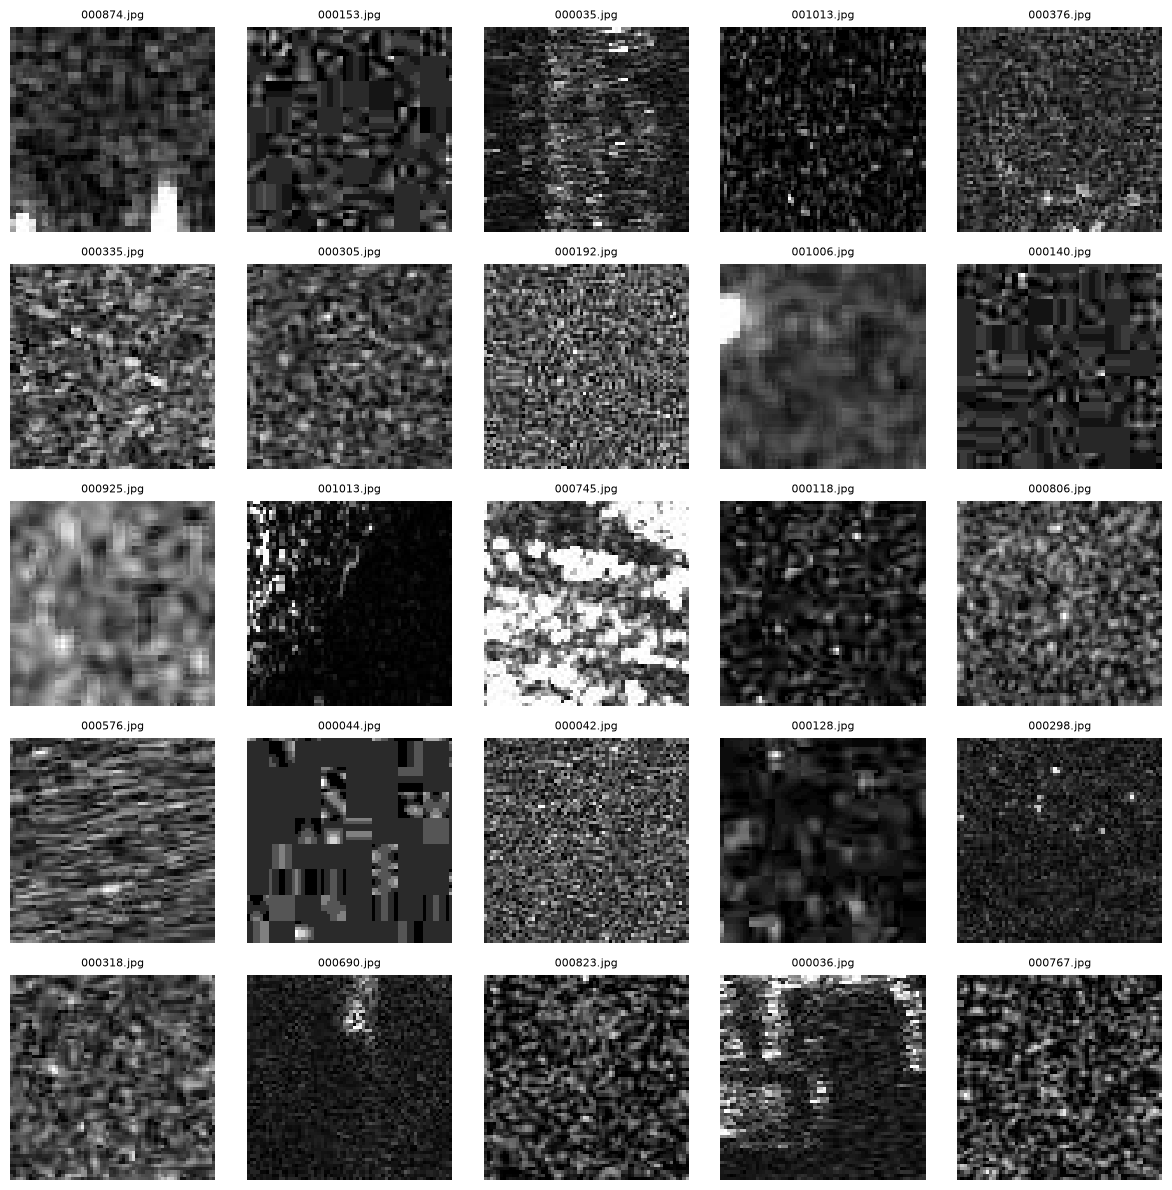

In [5]:
# Plotting
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
axes = axes.flatten()

for ax, item in zip(axes, samples):
    patch_path = PATCH_DIR / item["patch_filename"]
    image = cv2.imread(str(patch_path), cv2.IMREAD_GRAYSCALE)
    ax.imshow(image, cmap="gray")
    ax.set_title(item["source_image"], fontsize=8)
    ax.axis("off")


# Hiding unused axes
for ax in axes[len(samples):]:
    ax.axis("off")


plt.tight_layout()

output_path = (PROJECT_ROOT/"outputs"/"background_patch_examples.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=150, bbox_inches="tight")

print(f"Saved visualization to: {output_path}")

plt.show()